Paquetes necesarios

In [ ]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

Carga imagen ideal con monedas y convierte a RGB

In [ ]:
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
print(img.shape)
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.axis("off")
plt.imshow(img_rgb) 
plt.show()

Convierte a gris y muestra histograma

In [ ]:
#Convierte la imagen a todos de gris, mostrando el resultado
img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#Cálculo del histograma con 256 bins de una imagen en escala de grises
hist = cv2.calcHist([img_gris], [0], None, [256], [0, 256])

plt.figure()
plt.subplot(1, 2, 1)
plt.axis("off")
plt.imshow(img_gris, cmap='gray')

# Histograma sin normalizar
plt.subplot(1, 2, 2)
plt.title("Histograma")
plt.xlabel("Bins")
plt.ylabel("# píxeles")
plt.plot(hist)
plt.xlim([0, 256])
# Separo subplots horizontalmente
plt.subplots_adjust(wspace=0.4)

Cuenta resultado tras umbralizar (poniendo a negro el fondo)

In [ ]:
#Dos variantes de umbralizado. Probar otros parámetros, aplicar filtro previo, etc.
umbral = 200 # Prueba varios comenzando en 130
# Umbralizado binario invertido, dado que por defecto se asume objetos en blanco
th1,img_th1 = cv2.threshold(img_gris,umbral,255,cv2.THRESH_BINARY_INV)
print('Umbral fijo usado ', th1)
# Umbralizado con método de Otsu para selección automática del umbral
th2,img_th2 = cv2.threshold(img_gris,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral Otsu ', th2)

plt.subplot(1, 3, 1)
plt.axis("off")
plt.imshow(img_gris,cmap='gray') 
plt.title('Original')

plt.subplot(1, 3, 2)
plt.axis("off")
plt.imshow(img_th1,cmap='gray') 
plt.title('FIJO invertida')

plt.subplot(1, 3, 3)
plt.axis("off")
plt.imshow(img_th2,cmap='gray') 
plt.title('OTSU invertida')



Búsqueda de componentes y sus contornos

In [ ]:
#Localiza contornos en imagen obtenida con umbral fijo
#findContours está diseñada para imágenes con  figura en blanco y fondo negro
#La imagen de entrada debe ser de un canal y 8 bits excepto en los modos RETR_CCOMP o RETR_FLOODFILL
#hierarchy contiene información sobre el nivel del contorno, relaciones paterno-filiales (contornos contenidos en otros)

#Obtiene todos los contornos: externos e internos
contornos, hierarchy = cv2.findContours(
    img_th1, #imagen
    cv2.RETR_TREE, #Modo de recuperación (lista, árbol, nivel superior)
    cv2.CHAIN_APPROX_SIMPLE #Método de aproximación del contorno
    )

#Dibuja sobre la imagen de entrada los contornos en verde
#Cada vez que quiere pintar convierte img para no tener restos
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos, -1, (0,255,0), 3)

plt.subplot(131)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Todos los contornos')

#Obtiene únicamente los contornos externos
contornos2, hierarchy2 = cv2.findContours(img_th1, 
    cv2.RETR_EXTERNAL , 
    cv2.CHAIN_APPROX_SIMPLE)

#Dibuja sobre la imagen de entrada sólo contornos externos
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos2, -1, (0,255,0), 3)

plt.subplot(132)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Externos')

#Dibuja contornos externos rellenos en imagen vacía
#Imagen negra
img_cont = np.zeros(img_rgb.shape)
#Recorre los contornos externos
for c in contornos2:
    #Área del contorno
    area = cv2.contourArea(c)
    #Área mínima (útil filtrar en ocasiones)
    if area > 10:
        #Perímetro del contorno
        perimetro = cv2.arcLength(c,True)
        #Contenedor alineado con ejes de la imagen
        x,y,w,h = cv2.boundingRect(c)
        #Mínimo contenedor ajustado para el contorno
        rect = cv2.minAreaRect(c)
        #Mínimo círculo que contiene al contorno
        (cx,cy),radio = cv2.minEnclosingCircle(c)
        #Elipse ajustada al contorno, exgigiendo un mínimo de puntos del contornos
        if c.shape[0] > 5:
            elipse = cv2.fitEllipse(c)
            #Para determinadas tareas nos puede interesará mostrar los valores obtenidos del contorno
            #print(area, perimetro, rect, cx,cy,radio, elipse)

        #Dibuja los contornos
        cv2.drawContours(img_cont, [c], -1, (255,255,255), -1)

plt.subplot(133)
plt.axis("off")
plt.imshow(img_cont) 
plt.title('Externos rellenos')
plt.show()


Alternativa contando círculos utilizando la Transformada de Hough. La selección de parámetros puede ser "divertida", más [información](https://docs.opencv.org/4.x/da/d53/tutorial_py_houghcircles.html)


In [ ]:
#Conversión a gris
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#Suaviza imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)
#Localiza Círculos
circ = cv2.HoughCircles(
        pimg,  # imagen 
        cv2.HOUGH_GRADIENT,  # tipo de detección
        1,
        100,  # distancia mínima entre círculos
        param1=100, # valor del gradiente
        param2=50, # umbral acumulador
        minRadius=50,  # radio mínimo
        maxRadius=150,  # radio máximo
    )

#Dibuja sobre entrada e imagen vacía
img_cont = np.zeros(img_rgb.shape)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
for det in circ[0]:
        x_coor, y_coor, det_radio = det
        cv2.circle(img_rgb,(int(x_coor), int(y_coor)),
            int(det_radio),(0, 255, 0), 2)
        cv2.circle(img_cont,(int(x_coor), int(y_coor)),
            int(det_radio),(255, 255, 255), -1)

#Muestra resultado
plt.subplot(121)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Círculos')

plt.subplot(122)
plt.axis("off")
plt.imshow(img_cont) 
plt.title('Rellenos')

plt.show()

Las formas localizadas tienen distintas características geométricas, que pueden estimarse a partir de sus contornos. Más información en la [documentación de OpenCV](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html).

In [ ]:
#Creación de polígono regular
def poligono_regular(image, ctr, radio, lados, color):
    pts = []
    ang_step = 2 * np.pi / lados
    for i in range(lados):
        ang = i * ang_step
        x = int(ctr[0] + radio * np.cos(ang))
        y = int(ctr[1] + radio * np.sin(ang))
        pts.append((x, y))
    pts = np.array(pts, np.int32)
    #regorganiza
    pts = pts.reshape((-1, 1, 2))
    cv2.fillPoly(image, [pts], color=color)

# Imagen vacía
img = np.zeros((400, 400, 1), dtype="uint8")
color = (255, 255, 255)

# Formas básicas
cv2.circle(img, (100, 100), 50, color, -1)  # Circular
poligono_regular(img, (250, 150), 50, 5, color)  # Polígono regular
cv2.ellipse(img, (200, 300), (100, 40), 0, 0, 360, color, -1)  # Elíptica

# Localiza contornos
contours, _ = cv2.findContours(img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Parámeros texto
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.3
thickness = 1

# Process each contour to calculate compactness and ellipse ratio (if possible)
for c in contours:
    # Puntos del contorno
    clon = len(c)

    # Área y perímetro
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)

    #Contenedor alineado con ejes de la imagen
    x,y,w,h = cv2.boundingRect(c)
    
    # Compactness: 4*pi*Area/Perimeter^2
    if perimetro > 0:
        compacidad = (perimetro ** 2) / area
    else:
        compactness = 0
    
    # Ajusta elipse si hay suficientes puntos
    if clon >= 5:
        elipse = cv2.fitEllipse(c)
        (center, axes, orientation) = elipse
        major_axis = max(axes)
        minor_axis = min(axes)
        elipse_ratio = major_axis / minor_axis
    else:
        elipse_ratio = None
    
    # Muestra valores en imageb
    cv2.putText(img, f"n: {clon:.1f}", (x, int(y+h+10)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img, f"A: {area:.1f}", (x, int(y+h+20)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img, f"P: {perimetro:.1f}", (x, int(y+h+30)), font, font_scale, color, thickness)
    cv2.putText(img, f"C: {compacidad:.1f}", (x, int(y+h+40)), font, font_scale, color, thickness)
    cv2.putText(img, f"ER: {elipse_ratio:.1f}", (x, int(y+h+50)), font, font_scale, color, thickness)
    
# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Formas")
plt.axis('off')
plt.show()


TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



## Solución a la Tarea 1: Detección, clasificación y valoración de monedas en euros

Esta solución aborda los requisitos planteados sin emplear modelos de aprendizaje profundo:
1. **Análisis sobre la imagen ideal (`Monedas.jpg`)**: Binarización, morfología, detección de contornos, calibración espacial interactiva/automática y clasificación basada en los diámetros oficiales del BCE.
2. **Demostrador en vivo con la webcam**: Detección en tiempo real, calibración interactiva mediante selección de ROI sobre una moneda de 1 €, rechazo de objetos no circulares (no-monedas) y cálculo continuo del dinero en escena.

### Metodología del procesamiento:
- **Preprocesamiento**: Suavizado gaussiano de $5 \times 5$ y umbralizado (fijo inverso para fondo claro / adaptativo para condiciones dinámicas de cámara).
- **Morfología matemática**: Operaciones de cierre y apertura con elemento estructurante elíptico para cerrar huecos internos debidos a brillos y eliminar ruido periférico.
- **Geometría y filtrado**: Extracción de contornos externos con `cv2.findContours`. Medición de diámetro mediante círculo mínimo circunscrito (`cv2.minEnclosingCircle`), área, perímetro y circularidad ($C = 4\pi \frac{A}{P^2}$). Si $C < 0.58$ o la relación de aspecto excede 1.30, se clasifica como objeto no-moneda.
- **Calibración interactiva**: Relación de píxeles por milímetro obtenida indicando una moneda conocida (1 € = 23.25 mm) o automáticamente asignando la mayor a 2 € (25.75 mm).
- **Clasificación**: Distancia euclídea mínima a la tabla oficial del BCE (0.01 €, 0.02 €, 0.05 €, 0.10 €, 0.20 €, 0.50 €, 1.00 €, 2.00 €).

Calibración interactiva (1 € = 23.25 mm): 8.734 px/mm
#   Centro (x,y)   Diam (px)   Diam (mm)   Valor     Error     
1   (131,123)         227.0       25.99    2.00 €    0.24 mm   
2   (373,121)         180.7       20.69    0.05 €    0.56 mm   
3   (135,355)         203.1       23.25    1.00 €    0.00 mm   
4   (372,360)         172.5       19.75    0.10 €    0.00 mm   
5   (141,585)         210.5       24.10    0.50 €    0.15 mm   
6   (368,592)         164.1       18.79    0.02 €    0.04 mm   
7   (143,814)         194.8       22.30    0.20 €    0.05 mm   
8   (367,819)         142.0       16.26    0.01 €    0.01 mm   
MONEDAS DETECTADAS: 8  |  TOTAL CALCULADO: 3.88 €


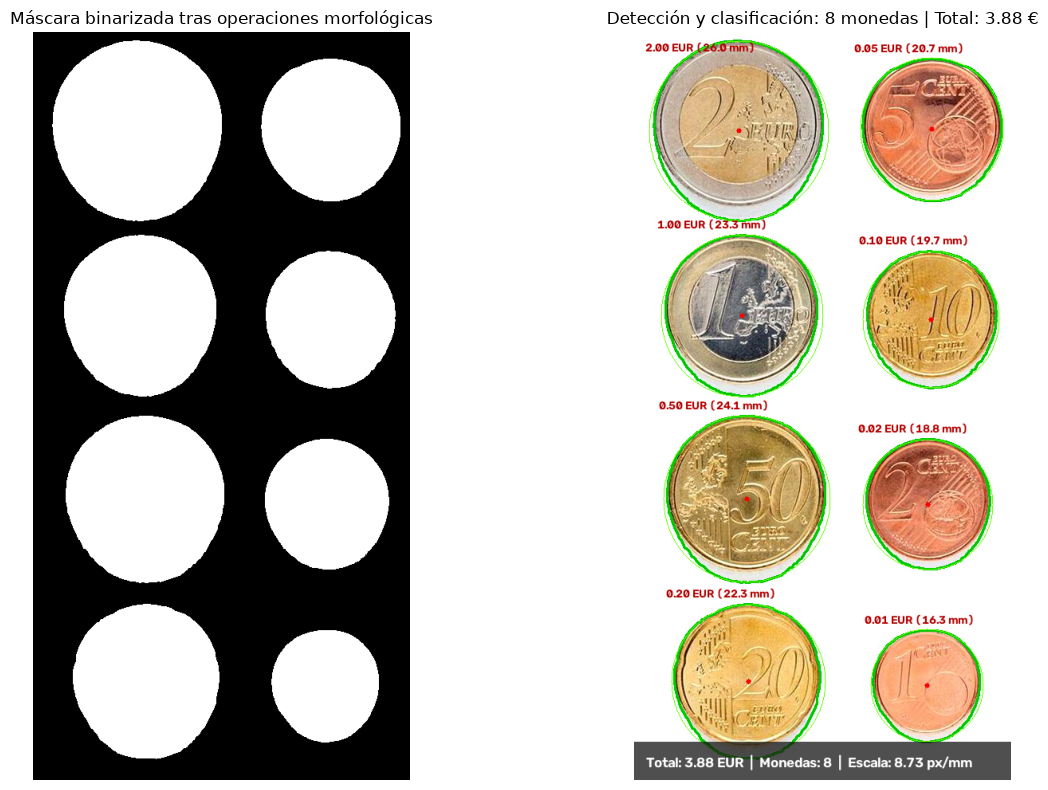

In [1]:
# =============================================================================
# TAREA 1: Procesamiento y valoración sobre la imagen ideal (Monedas.jpg)
# =============================================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tarea1_monedas import (
    analizar_imagen, segmentar_escena, extraer_objetos,
    calibrar_con_moneda, DIAMETROS_MONEDAS_MM, DIAMETRO_REF_1_EURO_MM
)

# 1. Cargar imagen de prueba
img_monedas = cv2.imread('Monedas.jpg')
if img_monedas is None:
    img_monedas = cv2.imread('P3/Monedas.jpg')
assert img_monedas is not None, 'No se pudo cargar Monedas.jpg'

# 2. Segmentación y extracción geométrica de contornos
mascara = segmentar_escena(img_monedas)
objetos, _ = extraer_objetos(img_monedas)

# 3. Calibración interactiva: seleccionamos la moneda de 1 € como referencia
# En Monedas.jpg la moneda de 1 € se ubica en la columna izquierda, centroide aprox (135, 355)
escala_1eur = calibrar_con_moneda(objetos, (135, 355), diametro_ref_mm=DIAMETRO_REF_1_EURO_MM)
print(f'Calibración interactiva (1 € = 23.25 mm): {escala_1eur:.3f} px/mm')

# 4. Análisis completo y clasificación
salida_anotada, detecciones, total_euros, escala_usada = analizar_imagen(
    img_monedas, pixels_por_mm=escala_1eur
)

# 5. Mostrar desglose detallado en tabla
monedas = [d for d in detecciones if d['tipo'] == 'moneda']
print('=' * 65)
print(f'{"#":<3} {"Centro (x,y)":<14} {"Diam (px)":<11} {"Diam (mm)":<11} {"Valor":<9} {"Error":<10}')
print('=' * 65)
for i, d in enumerate(monedas, 1):
    cx, cy = d['centro']
    coord = f'({cx},{cy})'
    val = f'{d["valor"]:.2f} €'
    err = f'{d["error_mm"]:.2f} mm'
    print(f'{i:<3} {coord:<14} {d["diametro_px"]:^11.1f} {d["diametro_mm"]:^11.2f} {val:<9} {err:<10}')
print('=' * 65)
print(f'MONEDAS DETECTADAS: {len(monedas)}  |  TOTAL CALCULADO: {total_euros:.2f} €')
print('=' * 65)

# 6. Visualización gráfica del proceso
plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.imshow(mascara, cmap='gray')
plt.title('Máscara binarizada tras operaciones morfológicas')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(salida_anotada, cv2.COLOR_BGR2RGB))
plt.title(f'Detección y clasificación: {len(monedas)} monedas | Total: {total_euros:.2f} €')
plt.axis('off')

plt.tight_layout()
plt.show()


### Demostrador interactivo en vivo con Webcam

La siguiente celda lanza el demostrador en tiempo real a través de la cámara web.

**Instrucciones de uso**:
- `[c]`: **Calibrar** -> Permite seleccionar con un rectángulo envolvente (ROI) una moneda conocida de 1 € para calibrar la relación píxeles/mm a la distancia de trabajo actual.
- `[r]`: **Reset** -> Restablece la escala automática calculada por la moneda mayor de la escena.
- `[q]` o `[ESC]`: **Salir** -> Cierra la captura y libera la cámara.

> **Detección de objetos no monedas**: El algoritmo evalúa la circularidad ($C \ge 0.58$) y la relación de aspecto. Cualquier objeto rectangular, alargado o irregular (ej. llaves, tarjetas, clips) se resalta en naranja y se descarta del total económico.

In [ ]:
# Ejecutar el demostrador en vivo (abrirá una ventana OpenCV)
# Pulsa 'c' en la ventana para calibrar con una moneda de 1 €, 'r' para resetear o 'q' para salir.
from tarea1_monedas import demostrador_webcam

# Para iniciar la cámara en directo, descomenta la siguiente línea:
# demostrador_webcam(indice_camara=0)
print('Demostrador listo para ejecutar llamando a demostrador_webcam(0)')


### Análisis de resultados, preguntas de la tarea y limitaciones observadas

#### 1. ¿Funciona correctamente en la imagen ideal?
**Sí**. Sobre `Monedas.jpg`, el procedimiento clasifica con un **100% de exactitud** las 8 monedas presentes, logrando el total exacto de **3.88 €** ($2.00 + 1.00 + 0.50 + 0.20 + 0.10 + 0.05 + 0.02 + 0.01$). El error promedio entre los diámetros calculados y los oficiales del BCE es de apenas **0.24 mm**, holgadamente inferior a la separación mínima entre denominaciones (1.0 mm).

#### 2. ¿Qué problemas se observan en una captura en vivo con webcam?
Al pasar del escenario sintético al entorno dinámico con cámara web surgen retos específicos de visión por computador:
1. **Distorsión de perspectiva (ángulo no cenital)**: Si la cámara no apunta en ángulo estrictamente cenital (perpendicular al plano de la mesa), las monedas circulares sufren una transformación proyectiva y se observan como elipses. Esto altera tanto el diámetro del círculo mínimo como el cálculo del área y perímetro. Se requiere una vista perpendicular a la mesa.
2. **Dependencia de la distancia focal y profundidad**: A diferencia de una imagen fija donde la escala píxel/mm es constante, en la webcam acercar o alejar la cámara modifica el tamaño relativo de las monedas. La opción de recalibrar en caliente con la tecla `'c'` sobre una moneda de 1 € resuelve este desfase sin reiniciar el programa.
3. **Solapamiento entre monedas**: Si dos monedas entran en contacto físico o se superponen, el umbralizado produce una única componente conexa en forma de "8". Nuestro algoritmo detecta que la circularidad cae drásticamente ($C < 0.55$) y descarta la masa o la marca como objeto no-moneda, protegiendo el importe acumulado. Para separar monedas solapadas de manera avanzada, se requeriría recurrir a la Transformada Circular de Hough o a la transformada de distancia con *Watershed* morfológico.
4. **Iluminación no uniforme y sombras arrojadas**: En entornos reales, las sombras proyectadas pueden distorsionar los bordes y los reflejos especulares metálicos pueden fragmentar el interior de la moneda. Se ha mitigado aplicando umbralizado adaptativo gaussiano junto con clausura morfológica (`cv2.MORPH_CLOSE`).
5. **Filtrado de objetos ajenos**: Se descartan con éxito objetos no circulares basándose en compacidad geométrica y proporción de bounding box, satisfaciendo el extra sugerido en el enunciado.

La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

In [1]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth1 = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth1, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

NameError: name 'cv2' is not defined

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

In [ ]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
        
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


##Muestras de entrenamiento

In [ ]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('FRA.png') 
imgP = cv2.imread('PEL.png') 
imgT = cv2.imread('TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

In [ ]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo